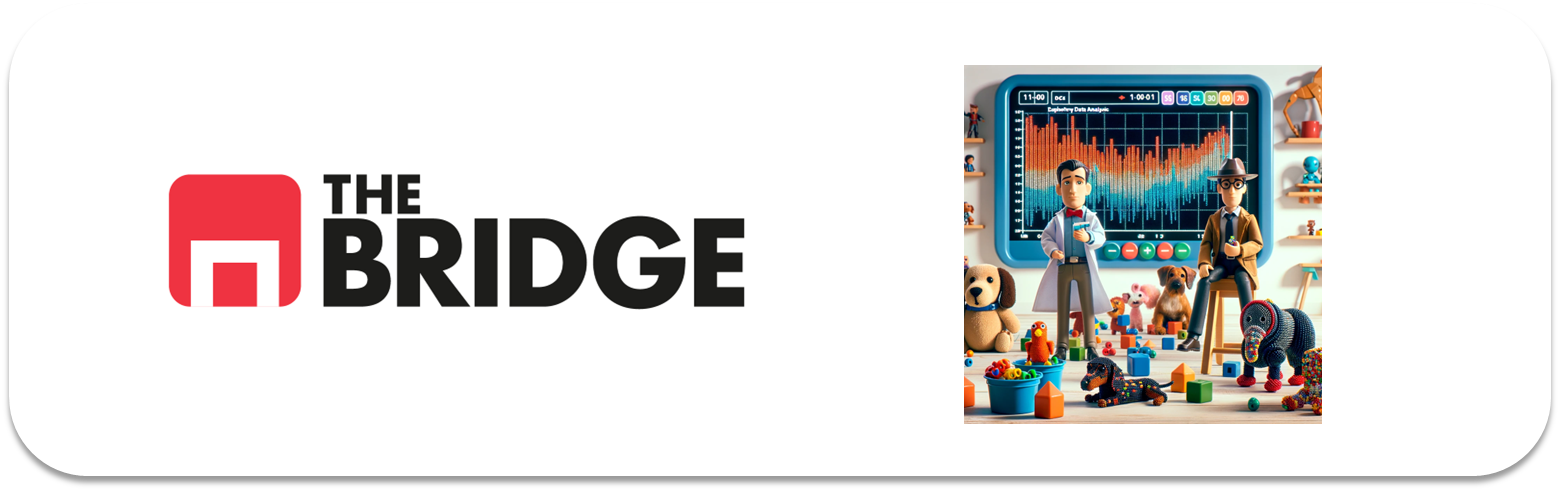

## PRACTICA OBLIGATORIA: ANÁLISIS MULTIVARIANTE

### Ejercicio 0


Importa los paquetes y módulos que necesites a lo largo del notebook

In [2]:
#    https://www.data-to-viz.com/#stackedarea
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from bootcampviztools import plot_combined_graphs, pinta_distribucion_categoricas, plot_categorical_relationship_fin,\
      plot_grouped_boxplots,plot_grouped_histograms, grafico_dispersion_con_correlacion, plot_categorical_numerical_relationship
from scipy.stats import pearsonr
import scipy.stats as stats

## #1 TITANIC

### #1.1

Carga en un dataframe el dataset del titanic, que está en la ruta "./data/titanic.csv".

In [29]:
titanic=pd.read_csv("titanic.csv")
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


### #1.2

Deshazte de las columnas "deck", "survived", "pclass" y "embarked" porque no las emplearemos, la primera por su cantidad de nulos y el resto porque son variantes de otras que ya existen y cuyos valores resultan más expresivos a la hora de hacer un análisis. 

In [30]:
titanic.drop(columns=["deck","survived","pclass","embarked"], inplace=True)
titanic

,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone
0,male,22.0,1,0,7.2500,Third,man,True,Southampton,no,False
1,female,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False
2,female,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True
3,female,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False
4,male,35.0,0,0,8.0500,Third,man,True,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,0,0,13.0000,Second,man,True,Southampton,no,True
887,female,19.0,0,0,30.0000,First,woman,False,Southampton,yes,True
888,female,NaN,1,2,23.4500,Third,woman,False,Southampton,no,False
889,male,26.0,0,0,30.0000,First,man,True,Cherbourg,yes,True


### #1.3

Suma las columnas "parch" y "sibsp" para tener el número de parientes de cada pasajero, guarda el resultado en otra columna "family_members", luego deshazte de "parch" y "sibsp"

In [31]:
titanic["family_members"]=titanic["parch"]+titanic["sibsp"]
titanic

,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,family_members
0,male,22.0,1,0,7.2500,Third,man,True,Southampton,no,False,1
1,female,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False,1
2,female,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True,0
3,female,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False,1
4,male,35.0,0,0,8.0500,Third,man,True,Southampton,no,True,0
...,...,...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,0,0,13.0000,Second,man,True,Southampton,no,True,0
887,female,19.0,0,0,30.0000,First,woman,False,Southampton,yes,True,0
888,female,NaN,1,2,23.4500,Third,woman,False,Southampton,no,False,3
889,male,26.0,0,0,30.0000,First,man,True,Cherbourg,yes,True,0


In [32]:
titanic.drop(columns=["parch","sibsp"], inplace=True)
titanic

,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members
0,male,22.0,7.2500,Third,man,True,Southampton,no,False,1
1,female,38.0,71.2833,First,woman,False,Cherbourg,yes,False,1
2,female,26.0,7.9250,Third,woman,False,Southampton,yes,True,0
3,female,35.0,53.1000,First,woman,False,Southampton,yes,False,1
4,male,35.0,8.0500,Third,man,True,Southampton,no,True,0
...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,13.0000,Second,man,True,Southampton,no,True,0
887,female,19.0,30.0000,First,woman,False,Southampton,yes,True,0
888,female,NaN,23.4500,Third,woman,False,Southampton,no,False,3
889,male,26.0,30.0000,First,man,True,Cherbourg,yes,True,0


### #1.4

Imputa la moda a los valores nulos de "embark_town"

In [33]:
titanic["embark_town"]=titanic["embark_town"].fillna(titanic["embark_town"].mode()[0])
titanic

,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members
0,male,22.0,7.2500,Third,man,True,Southampton,no,False,1
1,female,38.0,71.2833,First,woman,False,Cherbourg,yes,False,1
2,female,26.0,7.9250,Third,woman,False,Southampton,yes,True,0
3,female,35.0,53.1000,First,woman,False,Southampton,yes,False,1
4,male,35.0,8.0500,Third,man,True,Southampton,no,True,0
...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,13.0000,Second,man,True,Southampton,no,True,0
887,female,19.0,30.0000,First,woman,False,Southampton,yes,True,0
888,female,NaN,23.4500,Third,woman,False,Southampton,no,False,3
889,male,26.0,30.0000,First,man,True,Cherbourg,yes,True,0


In [34]:
titanic["embark_town"].isna().any()

np.False_

### #1.5

Imputa la media a los valores faltantes de "age", si quieres puedes hacer algo más preciso (por ejemplo considerando además la columna "who")

In [35]:
titanic['age'] = titanic['age'].fillna(titanic.groupby(['sex','class','who'])['age'].transform('median'))
titanic

,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members
0,male,22.0,7.2500,Third,man,True,Southampton,no,False,1
1,female,38.0,71.2833,First,woman,False,Cherbourg,yes,False,1
2,female,26.0,7.9250,Third,woman,False,Southampton,yes,True,0
3,female,35.0,53.1000,First,woman,False,Southampton,yes,False,1
4,male,35.0,8.0500,Third,man,True,Southampton,no,True,0
...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,13.0000,Second,man,True,Southampton,no,True,0
887,female,19.0,30.0000,First,woman,False,Southampton,yes,True,0
888,female,26.0,23.4500,Third,woman,False,Southampton,no,False,3
889,male,26.0,30.0000,First,man,True,Cherbourg,yes,True,0


### 1.6

Realiza los análisis bivariantes o multivariantes que necesites, así como los test de hipótesis necesarios para contestar a las siguientes preguntas. Nota: utiliza la variable "alive" para saber si un pasajero sobrevivió o no:

1. En términos absolutos, ¿sobrevivieron más hombres, mujeres o niños? ¿Y en términos relativos? ¿Existe alguna relación estadísticamente significativa entre el sexo y la supervivencia en el Titanic?¿Y entre ser adulto o ser niño?

2. En términos absolutos, ¿de que clase sobrevivieron más pasajeros?¿ Y en términos relativos? ¿Existe alguna relación estadísticamente significativa entre la clase en la que se viajaba y la supervivencia?

3. ¿De qué ciudad sobrevivieron más personas?¿Y porcentualmente de que ciudad sobrevivieron más personas? ¿Hay alguna relación estadística significativa entre haber embarcado en una de las tres ciudades y haber sobrevivido o fallecido?

4. ¿Qué relación hay entre el precio del pasaje y la supervivencia/fallecimiento?

5. Existen pasajeros que no pagaron el billete, ¿podrías explicar por qué? ¿Qué ocurrió con la persona que más dinero se dejó?

6. Existe alguna relación entre el dinero pagado, la ciudad de embarque y la superviviencia/fallecimiento. No necesitas aplicar ningún test, muestralo numérica o visualmente.

7. Ahondando en la relación entre sobrevivir o fallecer, la clase en la que se viajó y la edad de los pasajeros. ¿Qué agrupación de las dos variables (clase y edad) sobrevivió más en términos absolutos y en términos relativos?

8. Finalmente, muestra las posibles relaciones entre edad, coste del billete y supervivencia/fallecimiento. ¿Qué puedes decir al respecto?

#### #1

In [36]:
print(titanic[titanic["who"]=="man"].shape[0])
print(titanic[(titanic["alive"]=="yes")&(titanic["who"]=="man")].shape[0])

print(titanic[titanic["who"]=="woman"].shape[0])
print(titanic[(titanic["alive"]=="yes")&(titanic["who"]=="woman")].shape[0])

print(titanic[titanic["who"]=="child"].shape[0])
print(titanic[(titanic["alive"]=="yes")&(titanic["who"]=="child")].shape[0])

537
88
271
205
83
49


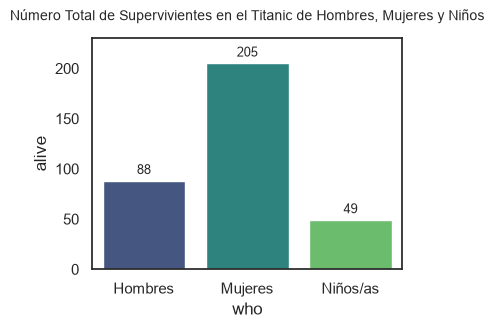

In [37]:
# SUPERVIVENCIA POR WHO EN TÉRMINOS ABSOLUTOS

sns.set_theme(style="white")
plt.figure(figsize=(4, 3)) #anchura,altura

ax = sns.barplot(data=titanic, x="who", y=titanic["alive"].eq("yes").astype(int), estimator="sum",errorbar=None, palette="viridis", hue="who")

plt.title('Número Total de Supervivientes en el Titanic de Hombres, Mujeres y Niños', fontsize=10, pad=13)
plt.xticks([0, 1, 2], ['Hombres', 'Mujeres', 'Niños/as'])
plt.ylim(0, 230) #limite borde de arriba

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.show()

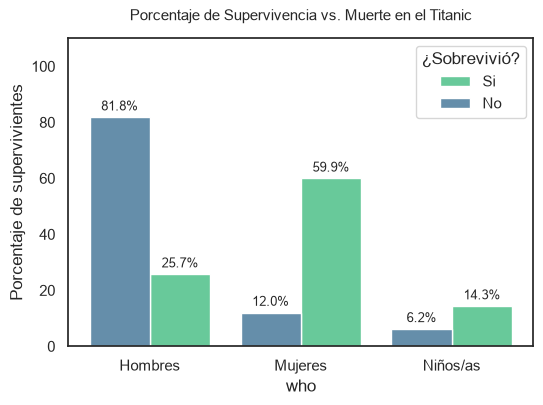

In [38]:
# SUPERVIVENCIA POR WHO EN TÉRMINOS RELATIVOS

sns.set_theme(style="white")
plt.figure(figsize=(6, 4))

# histplot calcula los porcentajes internos automáticamente
ax = sns.histplot(
    data=titanic,
    x="who",
    hue="alive",
    multiple="dodge", # pega las barras de 'yes' y 'no' una al lado de la otra
    stat="percent", # calcula el porcentaje
    common_norm=False, # hace que el porcentaje sea relativo a cada grupo de who
    palette="viridis",
    shrink=0.8 # separa ligeramente los bloques de barras de cada grupo para que se vea limpio
)

plt.title('Porcentaje de Supervivencia vs. Muerte en el Titanic', fontsize=11, pad=13)
plt.xlabel('who')
plt.ylabel('Porcentaje de supervivientes')
plt.xticks([0, 1, 2], ['Hombres', 'Mujeres', 'Niños/as'])
plt.ylim(0, 110)
plt.legend(title="¿Sobrevivió?", labels=["Si", "No"])

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)

plt.show()

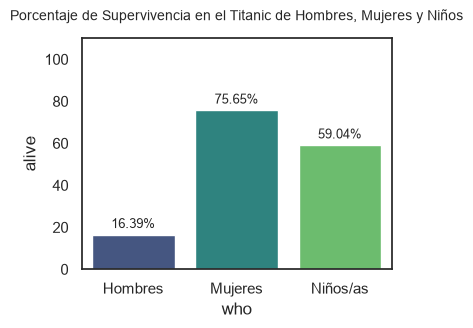

In [39]:
sns.set_theme(style="white")
plt.figure(figsize=(4, 3))

ax = sns.barplot(data=titanic, x="who", y=titanic["alive"].eq("yes")*100, errorbar=None, palette="viridis", hue="who")

plt.title('Porcentaje de Supervivencia en el Titanic de Hombres, Mujeres y Niños', fontsize=10, pad=13)
plt.xticks([0, 1, 2], ['Hombres', 'Mujeres', 'Niños/as'])
plt.ylim(0, 110)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=9)

plt.show()

#### #2

En términos absolutos, ¿de que clase sobrevivieron más pasajeros?¿ Y en términos relativos? ¿Existe alguna relación estadísticamente significativa entre la clase en la que se viajaba y la supervivencia?

In [40]:
print(titanic[titanic["class"]=="First"].shape[0])
print(titanic[(titanic["class"]=="First")&(titanic["alive"]=="yes")].shape[0])
print(titanic[titanic["class"]=="Second"].shape[0])
print(titanic[(titanic["class"]=="Second")&(titanic["alive"]=="yes")].shape[0])
print(titanic[titanic["class"]=="Third"].shape[0])
print(titanic[(titanic["class"]=="Third")&(titanic["alive"]=="yes")].shape[0])

216
136
184
87
491
119


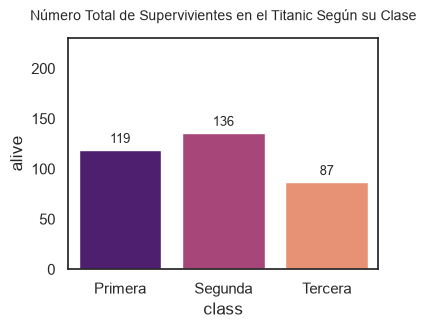

In [41]:
# SUPERVIVENCIA POR CLASS EN TÉRMINOS ABSOLUTOS

sns.set_theme(style="white")
plt.figure(figsize=(4, 3))

ax = sns.barplot(data=titanic, x="class", y=titanic["alive"].eq("yes").astype(int), estimator="sum",errorbar=None, palette="magma", hue="class")

plt.title('Número Total de Supervivientes en el Titanic Según su Clase', fontsize=10, pad=13)
plt.xticks([0, 1, 2], ['Primera', 'Segunda', 'Tercera'])
plt.ylim(0, 230)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.show()

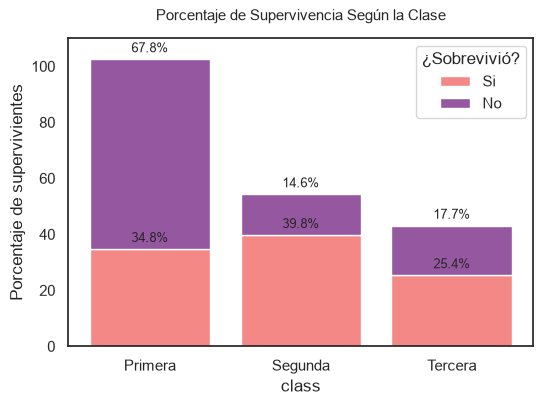

In [42]:
# SUPERVIVENCIA POR CLASS EN TÉRMINOS RELATIVOS

sns.set_theme(style="white")
plt.figure(figsize=(6, 4))

ax = sns.histplot(data=titanic, x="class", hue="alive", multiple="stack", stat="percent", common_norm=False, palette="magma", shrink=0.8)

plt.title('Porcentaje de Supervivencia Según la Clase', fontsize=11, pad=13)
plt.xlabel('class')
plt.ylabel('Porcentaje de supervivientes')
plt.xticks([0, 1, 2], ['Primera', 'Segunda', 'Tercera'])
plt.ylim(0, 110)
plt.legend(title="¿Sobrevivió?", labels=["Si", "No"])

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)

plt.show()

De nuevo, la relación entre pertencer a una clase u otra y sobrevivir o no es muy significativa. Se puede ver claramente que los primeros en ser evacuados fueron los pasajeros de primera clase

#### #3

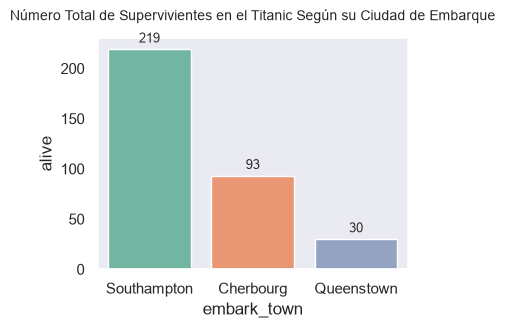

In [43]:
# SUPERVIVENCIA POR EMBARK_TOWN EN TÉRMINOS ABSOLUTOS

sns.set_theme(style="dark")
plt.figure(figsize=(4, 3))

ax = sns.barplot(data=titanic, x="embark_town", y=titanic["alive"].eq("yes").astype(int), estimator="sum",errorbar=None, palette="Set2", hue="embark_town")

plt.title('Número Total de Supervivientes en el Titanic Según su Ciudad de Embarque', fontsize=10, pad=13)
plt.xticks([0, 1, 2], ['Southampton', 'Cherbourg', 'Queenstown'])
plt.ylim(0, 230)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=9)

plt.show()

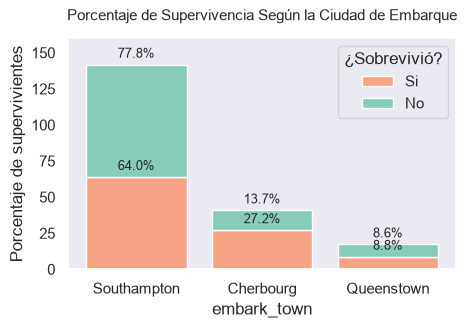

In [44]:
# SUPERVIVENCIA POR EMBARK_TOWN EN TÉRMINOS RELATIVOS

sns.set_theme(style="dark")
plt.figure(figsize=(5, 3))

ax = sns.histplot(data=titanic, x="embark_town", hue="alive", multiple="stack", stat="percent", common_norm=False, palette="Set2", shrink=0.8)

plt.title('Porcentaje de Supervivencia Según la Ciudad de Embarque', fontsize=11, pad=13)
plt.xlabel('embark_town')
plt.ylabel('Porcentaje de supervivientes')
plt.xticks([0, 1, 2], ['Southampton', 'Cherbourg', 'Queenstown'])
plt.ylim(0, 160)
plt.legend(title="¿Sobrevivió?", labels=["Si", "No"])

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)

plt.show()

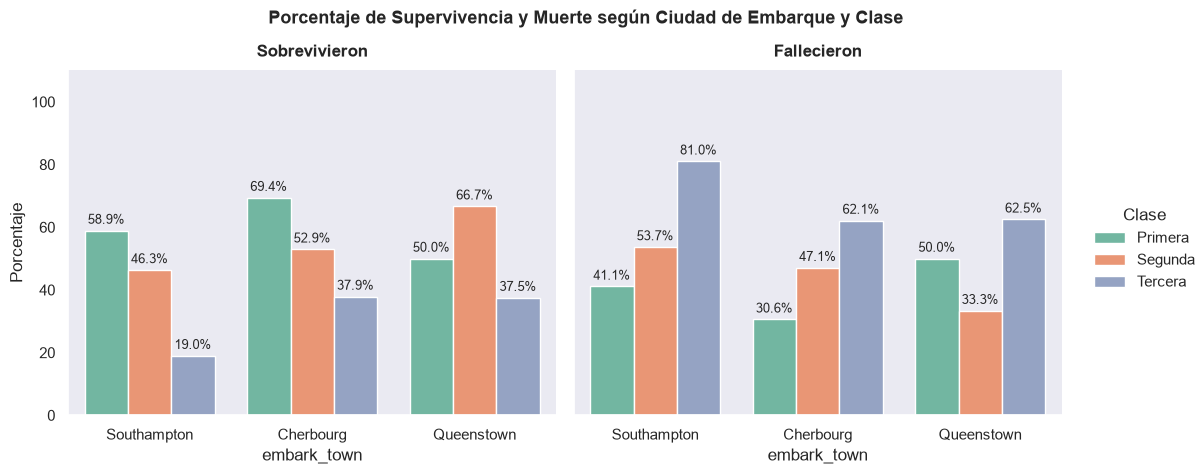

In [ ]:
####################################### REVISAR #######################################
sns.set_theme(style="dark")

#????????
df_pct = (titanic.groupby(['class', 'embark_town', 'alive'], dropna=False).size().reset_index(name='conteo'))

#????????
df_pct['porcentaje'] = df_pct.groupby(['class', 'embark_town'])['conteo'].transform(lambda x: (x / x.sum()) * 100)
df_pct = df_pct.dropna(subset=['embark_town'])

# gráfico multivariante con class, embark_town y alive con catplot
g = sns.catplot(data=df_pct, x="embark_town", y="porcentaje", hue="class", col="alive", kind="bar", palette="Set2",
                order=['Southampton', 'Cherbourg', 'Queenstown'], col_order=['yes', 'no'], height=4.5, aspect=1.2, legend=True)

for ax in g.axes.flat:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)

g.set_axis_labels("embark_town", "Porcentaje")
g.set_xticklabels(['Southampton', 'Cherbourg', 'Queenstown'])

g.axes.flat[0].set_title("Sobrevivieron", fontsize=12, fontweight='bold', pad=10)
g.axes.flat[1].set_title("Fallecieron", fontsize=12, fontweight='bold', pad=10)

for ax in g.axes.flat:
    ax.set_ylim(0, 110)

#????????
g._legend.set_title("Clase")
for text, label in zip(g._legend.texts, ["Primera", "Segunda", "Tercera"]):
    text.set_text(label)

g._legend.set_bbox_to_anchor((1.02, 0.5))

plt.suptitle('Porcentaje de Supervivencia y Muerte según Ciudad de Embarque y Clase', fontsize=13, fontweight='bold', y=1.05)

plt.show()

La relación entre la ciudad de embarque y sobrevivir o no también es destacable. Se puede observar que la mayoría de los que embarcaron en Southampton y la mitad de los de Queenstown fallecieron; sin embargo, la mayor parte de los que subieron al barco en Cherbourgo sobrevivieron. Esto se debe a que la mayoría de los de esta última ciudad eran de primera clase, y éstos fueron los primeros en ser evacuados.

#### #4

¿Qué relación hay entre el precio del pasaje y la supervivencia/fallecimiento?

In [46]:
titanic

,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members
0,male,22.0,7.2500,Third,man,True,Southampton,no,False,1
1,female,38.0,71.2833,First,woman,False,Cherbourg,yes,False,1
2,female,26.0,7.9250,Third,woman,False,Southampton,yes,True,0
3,female,35.0,53.1000,First,woman,False,Southampton,yes,False,1
4,male,35.0,8.0500,Third,man,True,Southampton,no,True,0
...,...,...,...,...,...,...,...,...,...,...
886,male,27.0,13.0000,Second,man,True,Southampton,no,True,0
887,female,19.0,30.0000,First,woman,False,Southampton,yes,True,0
888,female,26.0,23.4500,Third,woman,False,Southampton,no,False,3
889,male,26.0,30.0000,First,man,True,Cherbourg,yes,True,0


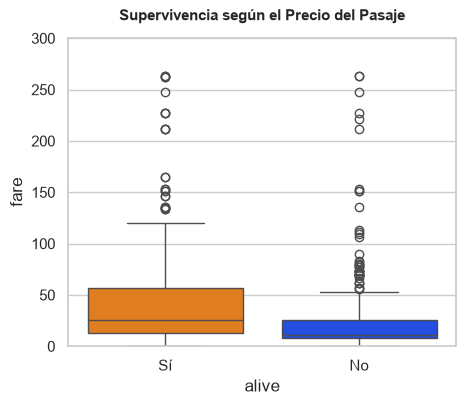

In [91]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(5, 4))

sns.boxplot(data=titanic, x="alive", y="fare", order=["yes", "no"], palette="bright", hue="alive")

plt.title('Supervivencia según el Precio del Pasaje', fontsize=11, pad=13, fontweight='bold')
plt.xlabel('alive')
plt.ylabel('fare')
plt.xticks([0,1], ['Sí','No'])
plt.ylim(0,300)

plt.show()

Vemos que tanto la mediana como los cuartiles de los billetes de los pasajes de los que sobrevivieron son bastante más altas. Como era de esperar, los billetes más caros generalmente pertenecían a los de las clases más altas y, por tanto, los primeros en ser evacuados del barco.

#### #5

In [48]:
titanic[titanic["fare"]==0].shape[0]

15

Hubo 15 personas que no pagaron billete, probablemente se deba a que eran trabajadores del barco.

In [49]:
print(titanic["fare"].max())
titanic[titanic["fare"]==512.3292] #Hasta tres personas pagaron 512.3292 por el pasaje más caro

512.3292


,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members
258,female,35.0,512.3292,First,woman,False,Cherbourg,yes,True,0
679,male,36.0,512.3292,First,man,True,Cherbourg,yes,False,1
737,male,35.0,512.3292,First,man,True,Cherbourg,yes,True,0


In [50]:
titanic[(titanic["alive"]=="yes")&(titanic["fare"]==512.3292)]

,sex,age,fare,class,who,adult_male,embark_town,alive,alone,family_members
258,female,35.0,512.3292,First,woman,False,Cherbourg,yes,True,0
679,male,36.0,512.3292,First,man,True,Cherbourg,yes,False,1
737,male,35.0,512.3292,First,man,True,Cherbourg,yes,True,0


Las tres personas que pagaron el pasaje más caro sobrevivieron al accidente.

#### #6

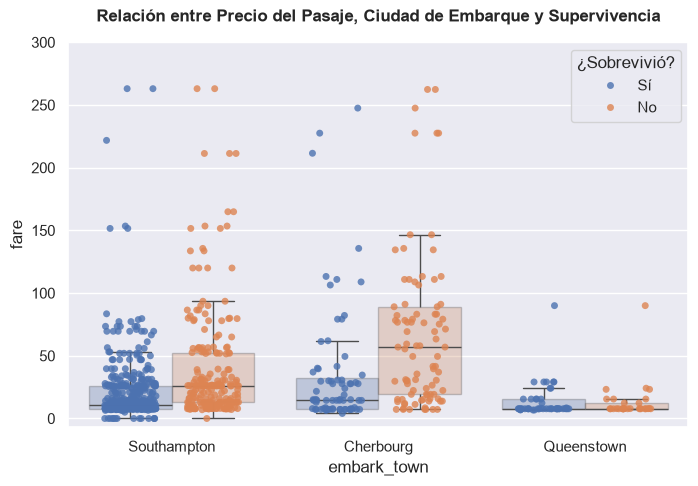

In [ ]:
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 5))

ax = sns.stripplot(data=titanic, x="embark_town", y="fare", hue="alive", palette="deep", jitter=0.25, size=5, alpha=0.8, dodge=True,
    order=['Southampton', 'Cherbourg', 'Queenstown'])

sns.boxplot(data=titanic, x="embark_town", y="fare", hue="alive", palette="deep",
    showfliers=False, # ocultar outliers
    ax=ax,
    boxprops=dict(alpha=0.3), # hacerlos transparentes
    order=['Southampton', 'Cherbourg', 'Queenstown']
)

plt.title('Relación entre Precio del Pasaje, Ciudad de Embarque y Supervivencia', fontsize=12, pad=15, fontweight='bold')
plt.xlabel('embark_town')
plt.ylabel('fare')
plt.xticks([0, 1, 2], ['Southampton', 'Cherbourg', 'Queenstown'])
plt.ylim(-7, 300)


handles, labels = ax.get_legend_handles_labels()
plt.legend(handles[0:2], ['Sí', 'No'], title="¿Sobrevivió?", loc='upper right')

plt.show()

Vemos que, en general, los que se montaron en Cherbourgo pagaron de media billetes más caros que los demás y, por tanto, sobrevivieron más personas de Cherbourgo que de otro lugar.

#### #7

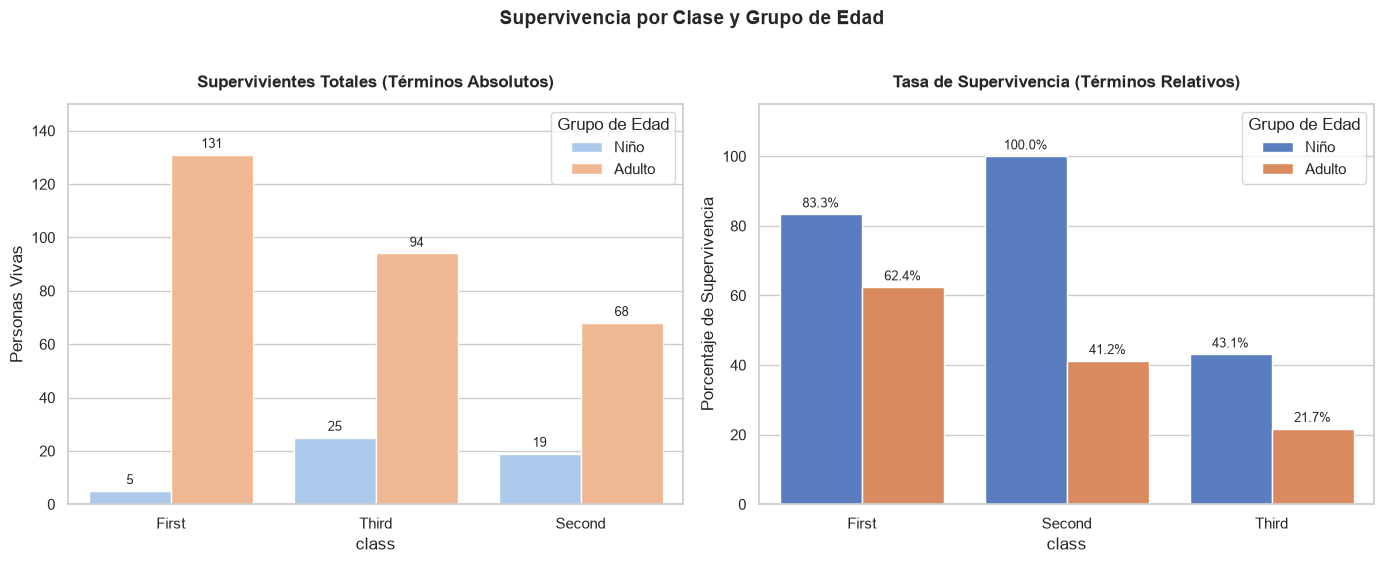

In [76]:
# creamos dos grupos de rangos de edad con pd.cut --> de 0 a 15 y de 16 a infinito, y llamadas Niño y Adulto
titanic['rango_edad'] = pd.cut(titanic['age'], bins=[0,15,np.inf], labels=['Niño','Adulto'])

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

######################### TÉRMINOS ABSOLUTOS #########################
df_vivos=titanic[titanic['alive']=='yes'] # solo los que sobreviven

ax1 = sns.countplot(data=df_vivos,x="class",hue="rango_edad",palette="pastel",ax=axes[0])
axes[0].set_title('Supervivientes Totales (Términos Absolutos)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('class')
axes[0].set_ylabel('Personas Vivas')
axes[0].set_ylim(0, 150)
axes[0].legend(title="Grupo de Edad")

for container in ax1.containers:
    ax1.bar_label(container, fmt='%d', padding=3, fontsize=9)



######################### TÉRMINOS RELATIVOS #########################
df_tasa_supervivencia = titanic.groupby(['class', 'rango_edad'], observed=False)['alive'].value_counts(normalize=True).reset_index(name='proporcion')
df_tasa_supervivencia['porcentaje']=df_tasa_supervivencia['proporcion']*100
df_relativo_vivos = df_pct[df_pct['alive']=='yes']

ax2 = sns.barplot(data=df_relativo_vivos, x="class", y="porcentaje", hue="rango_edad", palette="muted", ax=axes[1])
axes[1].set_title('Tasa de Supervivencia (Términos Relativos)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('class')
axes[1].set_ylabel('Porcentaje de Supervivencia')
axes[1].set_ylim(0, 115)
axes[1].legend(title="Grupo de Edad")

for container in ax2.containers:
    ax2.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)


plt.suptitle('Supervivencia por Clase y Grupo de Edad', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Los adultos que más sobrevivieron fueron los de primera clase tanto en términos absolutos como relativos. En porcentaje sobrevivieron más niños que adultos en todas las clases, al ser primera prioridad a la hora de ser evacuados.

#### #8

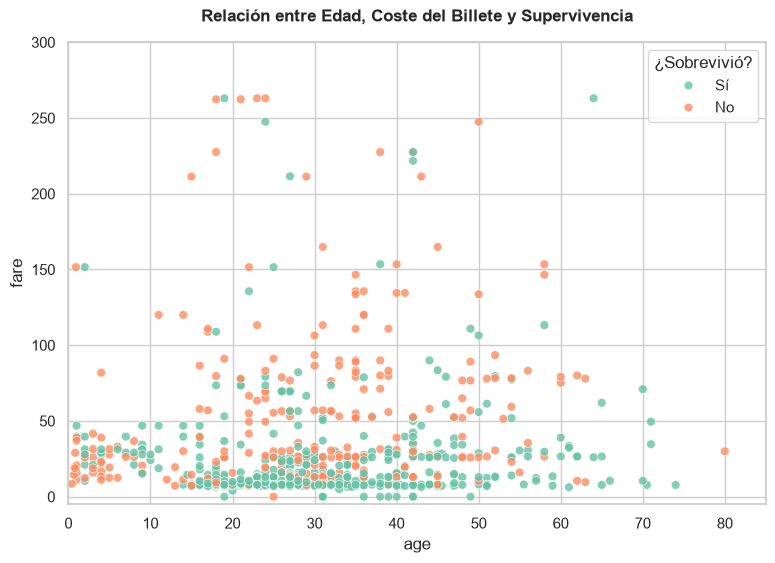

In [ ]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 6))

ax = sns.scatterplot(data=titanic, x="age", y="fare", hue="alive", palette="Set2", alpha=0.8, s=40)

plt.title('Relación entre Edad, Coste del Billete y Supervivencia', fontsize=12, pad=15, fontweight='bold')
plt.xlabel('age')
plt.ylabel('fare')
plt.ylim(-5,300)
plt.xlim(0,85)

# _ sirve para ignorar la segunda lista (labels, que son los textos originales en inglés), handles es una lista para guardar los círculos de colores
handles, _ = ax.get_legend_handles_labels()
plt.legend(handles=handles, labels=["Sí","No"], title="¿Sobrevivió?", loc='upper right')

plt.show()

## #2 Viajes

El objetivo en este caso no es tanto hacer un montón de análisis sino entender cómo de un dataset podemos obtener preguntas o hipótesis interesantes (si las hay)

### #2.1 

Carga el dataset de viajes del mes de junio. Repite el análisis bivariante entre las variables "Aircompany" e "Ingresos", mostrando previamente los viajes por compañía aérea. ¿Qué situación llamativa nos surgió? (Ten en cuenta que somos el departamenteo de DataScience de TabarAir)

In [79]:
df_viajes=pd.read_csv("dataset_viajes_A.csv")
df_viajes

,aircompany,origen,destino,distancia,avion,con_escala,consumo_kg,duracion,ingresos,id_vuelo,mes
0,Airnar,París,Ginebra,411,Boeing 737,False,1028.691900,51,14232.65,Air_PaGi_10737,Jun23
1,FlyQ,Bali,Roma,12738,Boeing 737,True,33479.132544,1167,468527.19,Fly_BaRo_10737,Jun23
2,TabarAir,Ginebra,Los Angeles,9103,Airbus A380,False,109439.907200,626,584789.19,Tab_GiLo_11380,Jun23
3,MoldaviAir,París,Cincinnati,6370,Boeing 737,False,17027.010000,503,233342.51,Mol_PaCi_10737,Jun23
4,TabarAir,Cincinnati,Roma,7480,Boeing 747,False,86115.744000,518,438535.07,Tab_CiRo_10747,Jun23
...,...,...,...,...,...,...,...,...,...,...,...
595,PamPangea,Bali,Londres,12553,Boeing 737,True,33310.138680,1153,442668.52,Pam_BaLo_10737,Jun23
596,Airnar,Cádiz,París,1447,Airbus A380,False,17229.139600,116,87307.63,Air_CaPa_11380,Jun23
597,Airnar,Los Angeles,Cádiz,9373,Boeing 737,False,23231.917800,731,339943.47,Air_LoCa_10737,Jun23
598,FlyQ,Barcelona,Bali,13058,Boeing 747,True,144766.211200,1070,752212.98,Fly_BaBa_10747,Jun23


In [81]:
df_viajes.isna().any().any()

np.False_

In [82]:
df_viajes[["aircompany","origen","destino","ingresos"]]

,aircompany,origen,destino,ingresos
0,Airnar,París,Ginebra,14232.65
1,FlyQ,Bali,Roma,468527.19
2,TabarAir,Ginebra,Los Angeles,584789.19
3,MoldaviAir,París,Cincinnati,233342.51
4,TabarAir,Cincinnati,Roma,438535.07
...,...,...,...,...
595,PamPangea,Bali,Londres,442668.52
596,Airnar,Cádiz,París,87307.63
597,Airnar,Los Angeles,Cádiz,339943.47
598,FlyQ,Barcelona,Bali,752212.98


In [83]:
df_viajes["aircompany"].nunique()

5

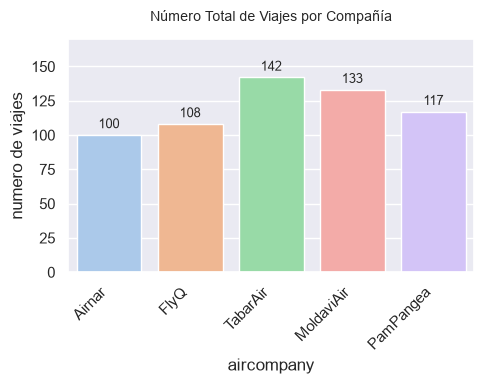

In [ ]:
sns.set_theme(style="darkgrid")
plt.figure(figsize=(5,4))

ax = sns.countplot(data=df_viajes, x="aircompany", palette="pastel", hue="aircompany", legend=False)

plt.title('Número Total de Viajes por Compañía', fontsize=10, pad=13)
plt.xlabel('aircompany')
plt.ylabel('numero de viajes')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 170)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontsize=9) # %d borra cualquier decimal que pueda haber

plt.tight_layout()
plt.show()

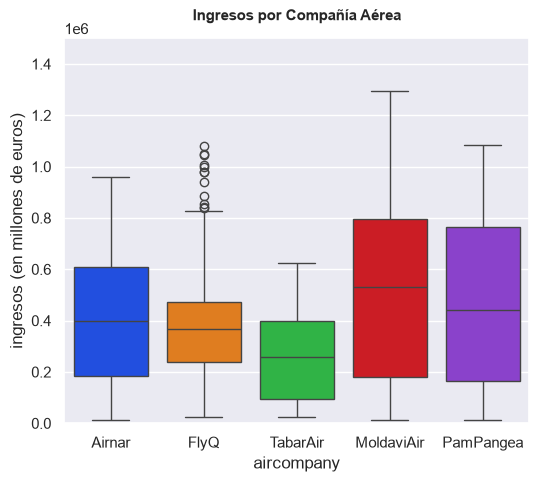

In [92]:
sns.set_theme(style="darkgrid")
plt.figure(figsize=(6, 5))

sns.boxplot(data=df_viajes, x="aircompany", y="ingresos",  palette="bright", hue="aircompany")
plt.title('Ingresos por Compañía Aérea', fontsize=11, pad=13, fontweight='bold')
plt.xlabel('aircompany')
plt.ylabel('ingresos (en millones de euros)')
plt.ylim(0,1500000)

plt.show()

Observamos que las compañías aéreas que más han recaudado por lo general son MoldaviAir y PamPangea. La única compañía con outliers -y bastantes además- es FlyQ.

Siendo data analysts de TabaAir, y habiendo visto los dos gráficos anteriores, se puede deducir que TabaAir es una compañía de vuelos muy baratos, ya que es de las que menos dinero han ingresado, siendo la compañía que más vuelos ha realizado en el último mes.

### #2.2

Repite el análisis multivariante entre "ingresos","distancias" y "consumo_kg". ¿Qué veíamos que parecía también muy prometedor?

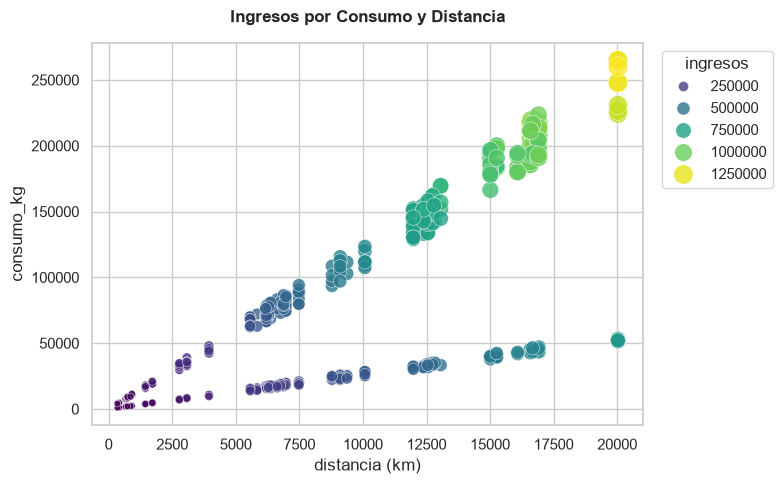

In [108]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_viajes, x="distancia", y="consumo_kg", hue="ingresos",
    size="ingresos", # cuanto más grandes sean los puntos, más ingresos
    sizes=(20, 200), palette="viridis", alpha=0.8)

plt.title('Ingresos por Consumo y Distancia', fontsize=12, pad=15, fontweight='bold')
plt.xlabel('distancia (km)')
plt.ylabel('consumo_kg')
plt.legend(title="ingresos", loc='upper left', bbox_to_anchor=(1.02, 1))

plt.tight_layout() #ajusta los márgenes para que los texto no se salgan o se pisen entre ellos
plt.show()

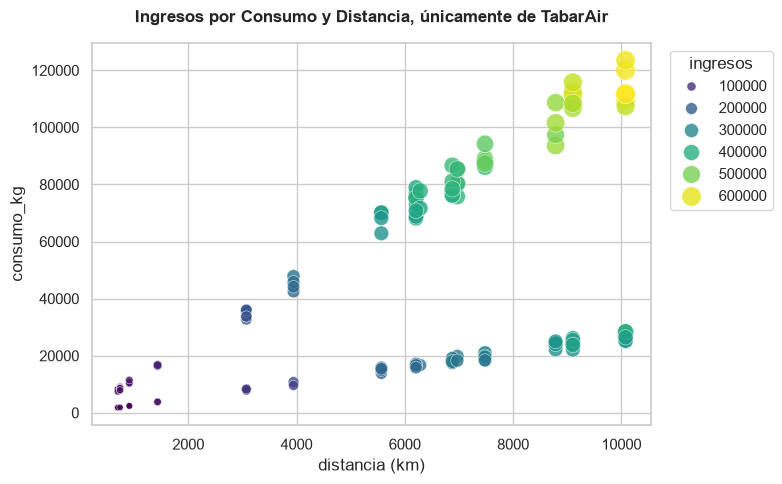

In [ ]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_viajes, x=df_viajes.loc[df_viajes["aircompany"]=="TabarAir","distancia"], y=df_viajes.loc[df_viajes["aircompany"]=="TabarAir","consumo_kg"],
                hue=df_viajes.loc[df_viajes["aircompany"]=="TabarAir","ingresos"], 
                size=df_viajes.loc[df_viajes["aircompany"]=="TabarAir","ingresos"], sizes=(20, 200), palette="viridis", alpha=0.8)

plt.title('Ingresos por Consumo y Distancia, únicamente de TabarAir', fontsize=12, pad=15, fontweight='bold')
plt.xlabel('distancia (km)')
plt.ylabel('consumo_kg')
plt.legend(title="ingresos", loc='upper left', bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

Observamos que los trayetos largos, por lo general, son los que más ingresos recaudan. Hay unos cuantos viajes anómalos, que consumen poco, tienen pocos ingresos y recorren muchos km. Podrían corresponderse a viajes en vacío de retorno.

Prometedor??????

### #2.3

Crea una variable categorica "cat_vuelo" a partir de distancias, escoge los rangos de las categorías basándote en la distribución de valores de "distancia" (sugerencia entre 3 y 4 categorías). Extra: Realiza ahora otra vez el análisis multivariante "cat_vuelo", "ingresos", "consumo_kg". ¿Ves algo diferente?

In [122]:
df_viajes['cat_vuelo'] = pd.cut(df_viajes['distancia'], bins=[0,7500,15000,np.inf], labels=['Corta distancia','Media distancia','Larga distancia'])
df_viajes

,aircompany,origen,destino,distancia,avion,con_escala,consumo_kg,duracion,ingresos,id_vuelo,mes,cat_vuelo
0,Airnar,París,Ginebra,411,Boeing 737,False,1028.691900,51,14232.65,Air_PaGi_10737,Jun23,Corta distancia
1,FlyQ,Bali,Roma,12738,Boeing 737,True,33479.132544,1167,468527.19,Fly_BaRo_10737,Jun23,Media distancia
2,TabarAir,Ginebra,Los Angeles,9103,Airbus A380,False,109439.907200,626,584789.19,Tab_GiLo_11380,Jun23,Media distancia
3,MoldaviAir,París,Cincinnati,6370,Boeing 737,False,17027.010000,503,233342.51,Mol_PaCi_10737,Jun23,Corta distancia
4,TabarAir,Cincinnati,Roma,7480,Boeing 747,False,86115.744000,518,438535.07,Tab_CiRo_10747,Jun23,Corta distancia
...,...,...,...,...,...,...,...,...,...,...,...,...
595,PamPangea,Bali,Londres,12553,Boeing 737,True,33310.138680,1153,442668.52,Pam_BaLo_10737,Jun23,Media distancia
596,Airnar,Cádiz,París,1447,Airbus A380,False,17229.139600,116,87307.63,Air_CaPa_11380,Jun23,Corta distancia
597,Airnar,Los Angeles,Cádiz,9373,Boeing 737,False,23231.917800,731,339943.47,Air_LoCa_10737,Jun23,Media distancia
598,FlyQ,Barcelona,Bali,13058,Boeing 747,True,144766.211200,1070,752212.98,Fly_BaBa_10747,Jun23,Media distancia


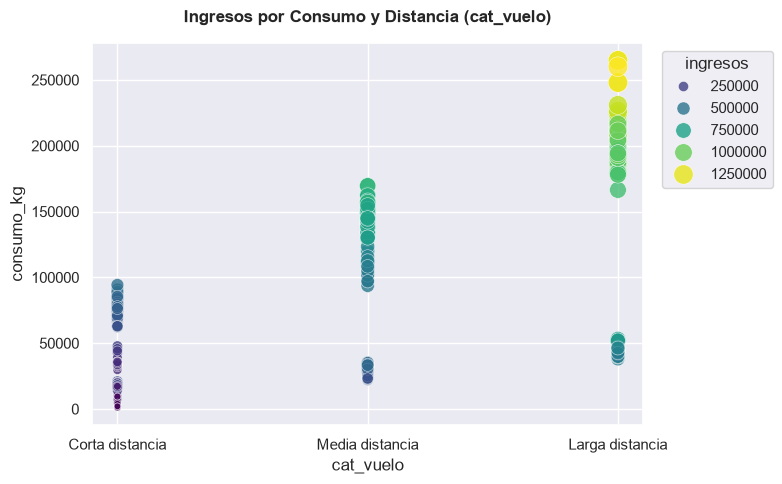

In [ ]:
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_viajes, x="cat_vuelo", y="consumo_kg", hue="ingresos", size="ingresos", sizes=(20, 200), palette="viridis", alpha=0.8)

plt.title('Ingresos por Consumo y Distancia (cat_vuelo)', fontsize=12, pad=15, fontweight='bold')
plt.xlabel('cat_vuelo')
plt.ylabel('consumo_kg')
plt.legend(title="ingresos", loc='upper left', bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

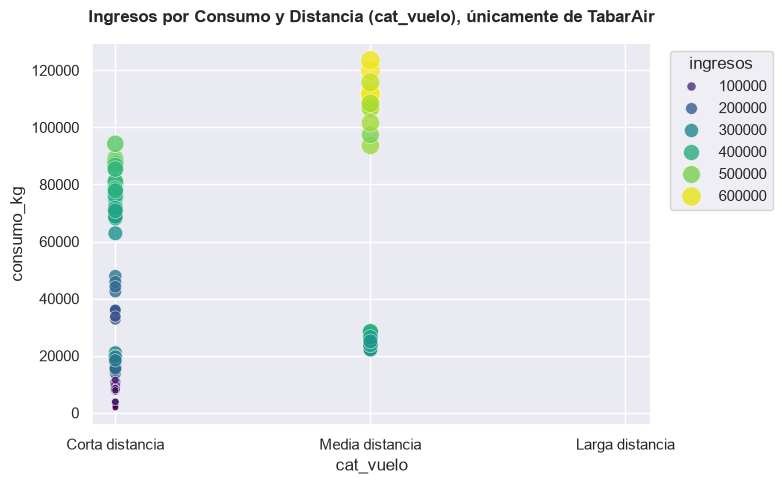

In [146]:
sns.set_theme(style="darkgrid")
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_viajes, x=df_viajes.loc[df_viajes["aircompany"]=="TabarAir","cat_vuelo"], y=df_viajes.loc[df_viajes["aircompany"]=="TabarAir","consumo_kg"],
                hue=df_viajes.loc[df_viajes["aircompany"]=="TabarAir","ingresos"], 
                size=df_viajes.loc[df_viajes["aircompany"]=="TabarAir","ingresos"], sizes=(20, 200), palette="viridis", alpha=0.8)

plt.title('Ingresos por Consumo y Distancia (cat_vuelo), únicamente de TabarAir', fontsize=12, pad=15, fontweight='bold')
plt.xlabel('cat_vuelo')
plt.ylabel('consumo_kg')
plt.legend(title="ingresos", loc='upper left', bbox_to_anchor=(1.02, 1))
plt.xlim(-0.09,2.1)

plt.tight_layout()
plt.show()

Al hacerlo de esta forma vemos que TabarAir únicamente realiza vuelos de corta y media distancia

### Extra:

#1 Consejos para encontrar "objetivos":

Si partes de un dataset que te parece interesante pero sin pregruntras claras, haz como hicimos con el dataset de Aviones. Describe, prioriza a ojo tus variables, realiza un análisis univariante completo, realiza un análisis bivariante ente las parejas de variables que te parecieron más intereantes. Llegados a este punto si el dataset tiene riqueza informativa, algo diferente tiene que haber aparecido (otra cosa es que sea interesante para ti :-)).  

Fíjate en lo que encontramos en el dataset de viajes: la empresa de más vuelos es la que menos ingresos tiene o la existencia clara de una línea de vuelos más eficientes en consumo que otros y otra de mayor ingresos por consumo. Lo siguiente es explorar esos puntos normalmente intentando contestar a: ¿por qué pasa?¿dónde,cuándo o cómo pasa?  

Busca esas "notas discordantes" en tu dataset, ya de por sí son mensajes del análisis. Ordénalas por importancia (importancia = impactan en ingresos, impactan en la calidad de la vida de las personas, impactan en el coste y poco más hay) e intenta entender por qué suceden esas notas discordantes, cómo solucionarlas o aprovecharlas y ya tienes objeetivos para el EDA; incluso si no encuentras respuesta siempre tendras esas notas discordantes, la conclusión de que no se puede avanzar con los datos que se tienen y los próximos pasos de encontrar más información para explicar lo que ocurre.

#2 Contestando a las preguntas de "Viajes".

- Necesitamos identificar esas líneas eficientes, para ello crea una variable que mida el ingreso por kilogramo consumido y otra que mida el kilogramo consumido por kilómetro. Haz el análisis univariante de las mismas intentando encontrar una diferencia clara entre viajes eficientes y no eficientes (que sabemos que existe). Fija un umbral para indicar si un viaje es supereficiente o si no lo es
- Crea esa variable de eficiencia binaria de eficiencia.
- Ahora haz el análisis bivariante de esa eficiencia y las compañías aéreas (queremos ver si realmente eso explica la situación de TabarAir). 
- Para nota: Hacer los análisis multivariante por compañía, eficiencia, tipo de avión y compañía, eficiencia, destino e incluso el de compañía, eficiencia, origen, destino.
- Con todo ello deberías poder encontrar si hay respuesta a la situación de TabarAir además de poder mostrar otros datos interesantes.